In [1]:
import numpy as np
import pandas as pd
import joblib 

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.metrics import classification_report, roc_auc_score, roc_curve, confusion_matrix, precision_recall_curve 

In [2]:
xgb_model_tuned = joblib.load(r"C:\Users\dhanu\OneDrive\Desktop\data_science_project\4_2_Model_Training_With_Tuning\Saved_Model\XGB_Tuned")

x_test = pd.read_csv(r"C:\Users\dhanu\OneDrive\Desktop\data_science_project\4_1_Model_Training\Training_and_Test_datasets\x_test")
y_test = pd.read_csv(r"C:\Users\dhanu\OneDrive\Desktop\data_science_project\4_1_Model_Training\Training_and_Test_datasets\y_test")

In [3]:
y_pred = xgb_model_tuned.predict(x_test)
y_pred_probs = xgb_model_tuned.predict_proba(x_test)[:, 1]

In [4]:
xgb_model = joblib.load(r"C:\Users\dhanu\OneDrive\Desktop\data_science_project\4_2_Model_Training_With_Tuning\Saved_Model\XGB_Tuned")

In [5]:
# Classification Report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.87      0.83      0.85      1035
           1       0.59      0.66      0.63       374

    accuracy                           0.79      1409
   macro avg       0.73      0.75      0.74      1409
weighted avg       0.80      0.79      0.79      1409



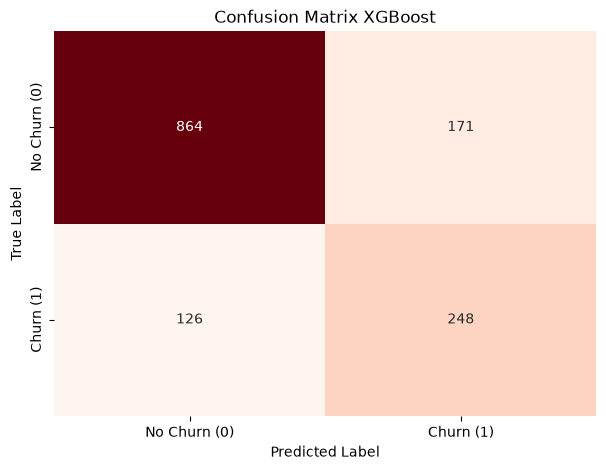

In [6]:
# Confusion Matrix

plt.figure(figsize = (7,5))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot = True, fmt = 'd', cmap  = "Reds", cbar = False, xticklabels = ["No Churn (0)", "Churn (1)"], yticklabels = ["No Churn (0)", "Churn (1)"])
plt.title("Confusion Matrix XGBoost")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

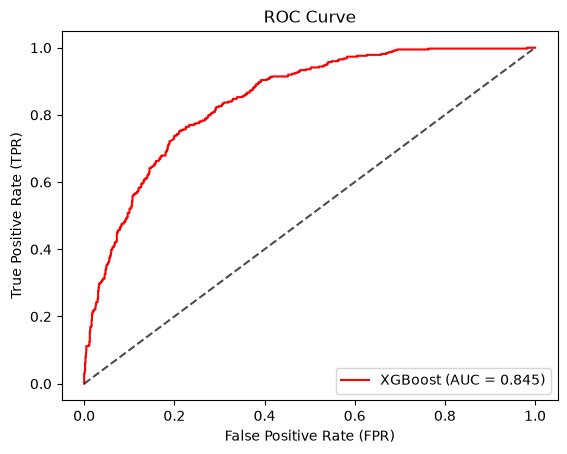

In [7]:
# ROC Curve

fpr, tpr, _ = roc_curve(y_test, y_pred_probs)
plt.plot(fpr, tpr, color = 'red', label = f"XGBoost (AUC = {roc_auc_score(y_test, y_pred_probs) :.3f})")
plt.plot([0,1], [0,1], 'k--', alpha = 0.7)
plt.title("ROC Curve")
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.legend(loc = 'lower right')
plt.show()

Accuracy : ~79%

Precision (Churn class) : ~59%

Recall (Churn class) : ~66%

Number of False Positives : 171

Number of False Negatives : 126

Number of True Positives : 248

Number of True Negatives : 864